# 05 — Inference & Explainability: Dataset 3 Held-Out SHAP Analysis

**Module Role (`src/inference`):** Runs held-out `shap.LinearExplainer` inference across all 10 repeated 5-fold `StratifiedGroupKFold` seeds for **Full fusion** vs **Fusion without ECOGPT1 and ECOGPT2**, verifies exact reproducibility against Experiment 23 OOF predictions, and generates the SHAP interpretation summary.

**Run Order:** Step 4 (loads saved Experiment 23 predictions from `04_evaluate_models_and_interpretation.ipynb` if present, or recomputes them identically on the fly).


## Setup: Load datasets, build cohort, define model helpers, and load OOF predictions


In [9]:
# Four-dataset analysis script
# Retains the original cohort/model logic and code for Experiments 17-26.
# Earlier exploratory sections (Experiments 1-16), duplicate audit material,
# and the separate correlation/agreement objective (Experiment 27) are omitted.
# Dataset 4 is loaded from its separately prepared processed CSV.
# Dataset 4 experiment counterparts run in an isolated section below.

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# Locate the new project's processed data folder.
PROJECT_DIR = None
DATA_DIR = None
for folder in [Path.cwd(), *Path.cwd().parents]:
    for candidate in (folder / "data" / "processed", folder / "processed_data"):
        if candidate.is_dir() and all(
            (candidate / filename).is_file()
            for filename in (
                "dataset1_storyteller.csv",
                "dataset2_ecog.csv",
                "primary_multimodal_30day_cohort.csv",
            )
        ):
            PROJECT_DIR = folder
            DATA_DIR = candidate
            break
    if DATA_DIR is not None:
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find a processed data folder containing the three dataset CSVs."
    )

RESULTS_ROOT = PROJECT_DIR / "results"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

# Load the three datasets used by the retained analyses.
dataset1_storyteller = pd.read_csv(
    DATA_DIR / "dataset1_storyteller.csv", low_memory=False
)
dataset2_ecog = pd.read_csv(
    DATA_DIR / "dataset2_ecog.csv", low_memory=False
)
dataset3_multimodal = pd.read_csv(
    DATA_DIR / "primary_multimodal_30day_cohort.csv", low_memory=False
)

# Normalize identifiers and targets without changing cohort membership.
for df in (dataset1_storyteller, dataset2_ecog, dataset3_multimodal):
    if "PTID" not in df or "TARGET" not in df:
        raise KeyError("Each dataset must contain PTID and TARGET columns.")
    df["PTID"] = df["PTID"].astype("string").str.strip()
    df["TARGET"] = pd.to_numeric(df["TARGET"], errors="coerce")
    if df[["PTID", "TARGET"]].isna().any().any():
        raise ValueError("A dataset contains missing PTID or TARGET values.")
    if not df["TARGET"].isin([0, 1]).all():
        raise ValueError("TARGET must contain only 0 and 1.")
    df["TARGET"] = df["TARGET"].astype(int)
    for col in df.columns:
        if "DATE" in str(col).upper():
            df[col] = pd.to_datetime(df[col], errors="coerce")

# Apply the feature exclusions used in the original predictor audit.
STORY_EXCLUDED_TERMS = ("PLAYBACK_COUNT", "GMATCH", "LANGUAGE")
story_feature_cols = [
    col for col in dataset1_storyteller.columns
    if str(col).upper().startswith("STORY")
    and not any(term in str(col).upper() for term in STORY_EXCLUDED_TERMS)
    and col in dataset3_multimodal.columns
]
ecog_feature_cols = [f"ECOGPT{i}" for i in range(1, 13)]

for name, df, features in (
    ("Dataset 1", dataset1_storyteller, story_feature_cols),
    ("Dataset 2", dataset2_ecog, ecog_feature_cols),
    ("Dataset 3", dataset3_multimodal, story_feature_cols + ecog_feature_cols),
):
    missing = [col for col in features if col not in df.columns]
    if missing:
        raise KeyError(f"{name} is missing predictor columns: {missing}")
    for col in features:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Loaded three datasets from:", DATA_DIR)
for name, df in (
    ("Dataset 1 - Storyteller", dataset1_storyteller),
    ("Dataset 2 - ECOG", dataset2_ecog),
    ("Dataset 3 - multimodal", dataset3_multimodal),
):
    print(
        f"{name}: {len(df)} rows, {df['PTID'].nunique()} participants, "
        f"targets={df['TARGET'].value_counts().sort_index().to_dict()}"
    )
print(
    f"Features: {len(story_feature_cols)} Storyteller, "
    f"{len(ecog_feature_cols)} ECOG, "
    f"{len(story_feature_cols) + len(ecog_feature_cols)} fusion"
)


Loaded three datasets from: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\data\processed
Dataset 1 - Storyteller: 1430 rows, 490 participants, targets={0: 1073, 1: 357}
Dataset 2 - ECOG: 501 rows, 397 participants, targets={0: 273, 1: 228}
Dataset 3 - multimodal: 77 rows, 71 participants, targets={0: 53, 1: 24}
Features: 51 Storyteller, 12 ECOG, 63 fusion


C:\Users\amnar\AppData\Local\Temp\ipykernel_75064\2858913358.py:64: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col], errors="coerce")


In [10]:
# Build the fixed 30-day common cohort and Exp 22 feature matrices
# (Exact deterministic logic from Fixed Cohort Temporal Window Comparison
#  and Nested Participant Grouped Feature Selection — unchanged.)

WINDOWS = {
    "30_days": 30,
    "90_days": 90,
    "180_days": 180,
    "365_days": 365,
    "historical": None,
}

STORY_DATE = "EXAMDATE_STORY"
ECOG_DATE = "COLDATE"
ID_COL = "PTID"
TARGET_COL = "TARGET"

story = dataset1_storyteller.copy()
ecog = dataset2_ecog.copy()

story[STORY_DATE] = pd.to_datetime(story[STORY_DATE], errors="coerce")
ecog[ECOG_DATE] = pd.to_datetime(ecog[ECOG_DATE], errors="coerce")

story = story.dropna(subset=[ID_COL, STORY_DATE, TARGET_COL]).copy()
ecog = ecog.dropna(subset=[ID_COL, ECOG_DATE]).copy()

story[TARGET_COL] = pd.to_numeric(story[TARGET_COL], errors="coerce")
story = story[story[TARGET_COL].isin([0, 1])].copy()

# ECOG value 9 means missing
for col in ecog_feature_cols:
    ecog[col] = pd.to_numeric(ecog[col], errors="coerce")
    ecog[col] = ecog[col].replace(9, np.nan)

ecog = ecog[ecog[ecog_feature_cols].notna().any(axis=1)].copy()

for col in story_feature_cols:
    story[col] = pd.to_numeric(story[col], errors="coerce")

story = story.reset_index(drop=True)
ecog = ecog.reset_index(drop=True)

ecog_by_id = {
    pid: group.sort_values(ECOG_DATE).copy()
    for pid, group in ecog.groupby(ID_COL)
}

eligible_indices = []
for idx, row in story.iterrows():
    pid = row[ID_COL]
    story_date = row[STORY_DATE]
    if pid not in ecog_by_id:
        continue
    participant_ecog = ecog_by_id[pid]
    eligible = participant_ecog[
        (participant_ecog[ECOG_DATE] <= story_date)
        & ((story_date - participant_ecog[ECOG_DATE]).dt.days <= 30)
    ]
    if len(eligible) > 0:
        eligible_indices.append(idx)

common_story = story.loc[eligible_indices].copy().reset_index(drop=True)

window_ecog_data = {}
for window_name, max_days in WINDOWS.items():
    records = []
    for _, row in common_story.iterrows():
        pid = row[ID_COL]
        story_date = row[STORY_DATE]
        participant_ecog = ecog_by_id.get(pid)
        if participant_ecog is None:
            continue
        eligible = participant_ecog[participant_ecog[ECOG_DATE] <= story_date].copy()
        eligible["GAP_DAYS"] = (story_date - eligible[ECOG_DATE]).dt.days
        if max_days is not None:
            eligible = eligible[eligible["GAP_DAYS"] <= max_days]
        if eligible.empty:
            continue
        aggregated = eligible[ecog_feature_cols].median()
        record = {
            "ROW_ID": row.name,
            ID_COL: pid,
            TARGET_COL: row[TARGET_COL],
            "N_ECOG_RECORDS": len(eligible),
            "LATEST_ECOG_GAP": eligible["GAP_DAYS"].min(),
            "OLDEST_ECOG_GAP": eligible["GAP_DAYS"].max(),
        }
        record.update(aggregated.to_dict())
        records.append(record)
    window_ecog_data[window_name] = pd.DataFrame(records)

# Build the exact Exp 22 feature matrices consumed by Experiments 23-26 and SHAP
story22 = common_story.copy().reset_index(drop=True)
ecog22 = window_ecog_data["30_days"].copy().reset_index(drop=True)

if len(story22) != len(ecog22):
    raise ValueError("Storyteller and ECOG row counts do not match.")
if "ROW_ID" in ecog22.columns and ecog22["ROW_ID"].tolist() != list(range(len(story22))):
    raise ValueError("ECOG ROW_ID alignment does not match the cohort.")

X_story22 = story22[story_feature_cols].apply(pd.to_numeric, errors="coerce").reset_index(drop=True)
X_ecog22 = ecog22[ecog_feature_cols].apply(pd.to_numeric, errors="coerce").reset_index(drop=True)
X_full22 = pd.concat([X_story22, X_ecog22], axis=1)
y22 = story22[TARGET_COL].astype(int).to_numpy()
groups22 = story22[ID_COL].to_numpy()

ecog_without_1 = [col for col in ecog_feature_cols if col != "ECOGPT1"]
ecog_without_2 = [col for col in ecog_feature_cols if col != "ECOGPT2"]
ecog_without_1_2 = [col for col in ecog_feature_cols if col not in ["ECOGPT1", "ECOGPT2"]]

candidate_features22 = {
    "Full_fusion": list(story_feature_cols) + list(ecog_feature_cols),
    "Without_ECOGPT1": list(story_feature_cols) + ecog_without_1,
    "Without_ECOGPT2": list(story_feature_cols) + ecog_without_2,
    "Without_ECOGPT1_ECOGPT2": list(story_feature_cols) + ecog_without_1_2,
}

print(
    f"Fixed 30-day cohort ready: {len(story22)} assessments, "
    f"{pd.Series(groups22).nunique()} participants "
    f"(CN={int((y22 == 0).sum())}, MCI={int((y22 == 1).sum())})"
)


Fixed 30-day cohort ready: 77 assessments, 71 participants (CN=53, MCI=24)


In [11]:
# Shared model pipeline, participant aggregation, and metric helpers
# (Exact definitions from Final Model Comparison and Uncertainty Analysis — unchanged.)

from collections import defaultdict
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEEDS_23 = [11, 21, 42, 52, 62, 72, 82, 92, 102, 112]
PRIMARY_SEED_23 = 42
N_SPLITS_23 = 5
THRESHOLD_23 = 0.50

X_story23 = X_story22.copy()
X_ecog23 = X_ecog22.copy()
X_full23 = X_full22.copy()
y23 = np.asarray(y22).astype(int)
groups23 = np.asarray(groups22)

feature_sets23 = {
    "Storyteller only": list(X_story23.columns),
    "Full fusion": list(X_full23.columns),
    "Fusion without ECOGPT1": [col for col in X_full23.columns if col != "ECOGPT1"],
    "Fusion without ECOGPT1 and ECOGPT2": [
        col for col in X_full23.columns if col not in ["ECOGPT1", "ECOGPT2"]
    ],
    "Fusion without ECOGPT2": [col for col in X_full23.columns if col != "ECOGPT2"],
}


def create_model23():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        (
            "classifier",
            LogisticRegression(
                max_iter=5000,
                class_weight="balanced",
                solver="liblinear",
                random_state=42,
            ),
        ),
    ])


def aggregate_participant_predictions23(y_true, participant_ids, probabilities):
    temp = pd.DataFrame({
        "PTID": participant_ids,
        "TARGET": y_true,
        "PROBABILITY": probabilities,
    })
    label_check = temp.groupby("PTID")["TARGET"].nunique()
    if (label_check > 1).any():
        raise ValueError("Inconsistent participant labels found during aggregation.")
    participant_predictions = (
        temp.groupby("PTID")
        .agg(
            TARGET=("TARGET", "first"),
            PROBABILITY=("PROBABILITY", "mean"),
            N_ASSESSMENTS=("TARGET", "size"),
        )
        .reset_index()
    )
    return participant_predictions


def calculate_metrics23(y_true, probabilities):
    predictions = (np.asarray(probabilities) >= THRESHOLD_23).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, predictions),
        "MCI_Precision": precision_score(y_true, predictions, zero_division=0),
        "MCI_Recall_Sensitivity": recall_score(y_true, predictions, zero_division=0),
        "Specificity": specificity,
        "MCI_F1": f1_score(y_true, predictions, zero_division=0),
        "Macro_F1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }


In [12]:
# Load saved participant-level OOF predictions from 04_evaluate_models_and_interpretation.ipynb
# (or compute them identically on the fly if the CSVs have not been generated yet).

RESULTS_DIR_23 = RESULTS_ROOT / "final_model_comparison_uncertainty" / "results"
SHAP_TARGET_MODELS = [
    "Full fusion",
    "Fusion without ECOGPT1 and ECOGPT2",
]

experiment23_predictions = defaultdict(dict)
loaded_from_disk = 0
computed_inline = 0

for seed in SEEDS_23:
    for model_name in SHAP_TARGET_MODELS:
        safe_name = (
            model_name.lower()
            .replace(" ", "_")
            .replace("+", "plus")
        )
        pred_csv = (
            RESULTS_DIR_23
            / f"final_model_comparison_uncertainty_seed_{seed}_{safe_name}_participant_predictions.csv"
        )
        if pred_csv.is_file():
            experiment23_predictions[seed][model_name] = pd.read_csv(pred_csv)
            loaded_from_disk += 1
        else:
            features = feature_sets23[model_name]
            X_model = X_full23[features].copy()
            cv = StratifiedGroupKFold(
                n_splits=N_SPLITS_23,
                shuffle=True,
                random_state=seed,
            )
            oof_prob = np.full(len(y23), np.nan, dtype=float)
            for train_idx, test_idx in cv.split(X_model, y23, groups23):
                model = create_model23()
                model.fit(X_model.iloc[train_idx], y23[train_idx])
                oof_prob[test_idx] = model.predict_proba(X_model.iloc[test_idx])[:, 1]
            experiment23_predictions[seed][model_name] = aggregate_participant_predictions23(
                y23, groups23, oof_prob
            )
            computed_inline += 1

print(
    f"experiment23_predictions ready for SHAP verification "
    f"(loaded from disk: {loaded_from_disk}, computed inline: {computed_inline})."
)


experiment23_predictions ready for SHAP verification (loaded from disk: 20, computed inline: 0).


## Dataset 3 SHAP Analysis: Full Fusion vs Reduced Fusion


In [13]:
# Dataset 3 SHAP analysis: full fusion vs reduced fusion
# Reduced fusion excludes ECOGPT1 and ECOGPT2.
# Run after the Final Model Comparison cell in adni4_analysis.ipynb.

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold


# ------------------------------------------------------------
# 1. Locate the project results folder
# ------------------------------------------------------------

if "RESULTS_ROOT" in globals():
    shap_results_root = Path(RESULTS_ROOT)

elif "PROJECT_DIR" in globals():
    shap_results_root = Path(PROJECT_DIR) / "results"

elif "DATA_DIR" in globals():
    data_dir = Path(DATA_DIR)
    project_dir = (
        data_dir.parent
        if data_dir.name in {"processed", "processed_data"}
        else data_dir
    )
    shap_results_root = project_dir / "results"

else:
    project_dir = None

    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data" / "processed" / "dataset3_multimodal.csv").is_file():
            project_dir = folder
            break

        if (folder / "processed_data" / "dataset3_multimodal.csv").is_file():
            project_dir = folder
            break

    if project_dir is None:
        raise FileNotFoundError(
            "Could not locate the project folder. Run this notebook from "
            "the project or notebooks folder."
        )

    shap_results_root = project_dir / "results"


SHAP_DIR = shap_results_root / "dataset3_shap_explainability"
SHAP_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Check that the original cohort and model variables exist
# ------------------------------------------------------------

SHAP_MODELS = [
    "Full fusion",
    "Fusion without ECOGPT1 and ECOGPT2",
]

required_variables = [
    "X_full23",
    "y23",
    "groups23",
    "feature_sets23",
    "SEEDS_23",
    "N_SPLITS_23",
    "PRIMARY_SEED_23",
    "create_model23",
    "aggregate_participant_predictions23",
    "calculate_metrics23",
    "experiment23_predictions",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "The SHAP cell needs variables created by earlier analysis cells: "
        f"{missing_variables}. In this notebook, run the dataset-loading, "
        "Temporal Window Sensitivity, Nested Participant Grouped Feature "
        "Selection, and Final Model Comparison cells first, in this same kernel."
    )

for model_name in SHAP_MODELS:
    if model_name not in feature_sets23:
        raise KeyError(
            f"Model not found in feature_sets23: {model_name}"
        )


# ------------------------------------------------------------
# 3. Refit the original folds and calculate held-out SHAP values
# ------------------------------------------------------------

shap_assessment_results = {}
shap_participant_results = {}
shap_metric_rows = []

for model_name in SHAP_MODELS:
    selected_features = feature_sets23[model_name]

    if model_name == "Full fusion":
        model_folder = "full_fusion"
    else:
        model_folder = "reduced_fusion_without_ECOGPT1_ECOGPT2"

    model_dir = SHAP_DIR / model_folder
    model_dir.mkdir(parents=True, exist_ok=True)

    assessment_rows = []

    for seed in SEEDS_23:
        # Use the same grouped folds as the model comparison.
        cv = StratifiedGroupKFold(
            n_splits=N_SPLITS_23,
            shuffle=True,
            random_state=seed,
        )

        splits = list(
            cv.split(
                X_full23,
                y23,
                groups=groups23,
            )
        )

        oof_probability = np.full(len(y23), np.nan)
        seed_rows = []

        for fold, (train_idx, test_idx) in enumerate(splits, start=1):
            train_groups = set(groups23[train_idx])
            test_groups = set(groups23[test_idx])

            if train_groups.intersection(test_groups):
                raise RuntimeError(
                    f"Participant leakage: seed={seed}, fold={fold}"
                )

            X_train = X_full23.iloc[train_idx][selected_features]
            X_test = X_full23.iloc[test_idx][selected_features]

            # Reuse the same imputer, scaler, and logistic regression.
            model = create_model23()
            model.fit(X_train, y23[train_idx])

            imputer = model.named_steps["imputer"]
            scaler = model.named_steps["scaler"]
            classifier = model.named_steps["classifier"]

            X_train_imputed = imputer.transform(X_train)
            X_test_imputed = imputer.transform(X_test)

            # Use the fitted scaler from the pipeline.
            X_train_transformed = scaler.transform(X_train_imputed)
            X_test_transformed = scaler.transform(X_test_imputed)

            feature_names = imputer.get_feature_names_out(
                selected_features
            ).tolist()

            # Make imputation-indicator names easy to recognize.
            feature_names = [
                name.replace("missingindicator_", "") + "__MISSING"
                if name.startswith("missingindicator_")
                else name
                for name in feature_names
            ]

            # Explain the logistic regression in log-odds units.
            explainer = shap.LinearExplainer(
                classifier,
                X_train_transformed,
            )
            shap_values = explainer.shap_values(X_test_transformed)

            if isinstance(shap_values, list):
                shap_values = shap_values[-1]

            shap_values = np.asarray(shap_values)

            if shap_values.ndim == 3:
                shap_values = shap_values[:, :, -1]

            expected_shape = (
                len(test_idx),
                len(feature_names),
            )

            if shap_values.shape != expected_shape:
                raise ValueError(
                    f"Unexpected SHAP dimensions for {model_name}: "
                    f"{shap_values.shape}; expected {expected_shape}"
                )

            probabilities = model.predict_proba(X_test)[:, 1]
            oof_probability[test_idx] = probabilities

            for local_i, row_idx in enumerate(test_idx):
                record = {
                    "PTID": str(groups23[row_idx]),
                    "TARGET": int(y23[row_idx]),
                    "Assessment_Row": int(row_idx),
                    "Seed": seed,
                    "Fold": fold,
                    "Probability_MCI": float(probabilities[local_i]),
                }

                record.update(
                    dict(
                        zip(
                            feature_names,
                            shap_values[local_i].astype(float),
                        )
                    )
                )

                seed_rows.append(record)

        if np.isnan(oof_probability).any():
            raise RuntimeError(
                f"Missing held-out predictions for {model_name}, seed {seed}."
            )

        # Aggregate assessment predictions to participant predictions,
        # matching the original model-comparison analysis.
        participant_predictions = aggregate_participant_predictions23(
            y23,
            groups23,
            oof_probability,
        )

        # Confirm the SHAP rerun reproduces the original CV probabilities.
        stored_predictions = (
            experiment23_predictions[seed][model_name]
            .sort_values("PTID")
            .reset_index(drop=True)
        )

        rerun_predictions = (
            participant_predictions
            .sort_values("PTID")
            .reset_index(drop=True)
        )

        if not np.array_equal(
            stored_predictions["PTID"].astype(str).to_numpy(),
            rerun_predictions["PTID"].astype(str).to_numpy(),
        ):
            raise AssertionError(
                f"Participant alignment differs for {model_name}, seed {seed}."
            )

        if not np.allclose(
            stored_predictions["PROBABILITY"].to_numpy(),
            rerun_predictions["PROBABILITY"].to_numpy(),
            atol=1e-12,
        ):
            raise AssertionError(
                f"Rerun predictions do not match the original predictions "
                f"for {model_name}, seed {seed}."
            )

        shap_metric_rows.append({
            "Model": model_name,
            "Seed": seed,
            "N_Participants": len(participant_predictions),
            **calculate_metrics23(
                participant_predictions["TARGET"],
                participant_predictions["PROBABILITY"],
            ),
        })

        assessment_rows.extend(seed_rows)

    assessment_shap = pd.DataFrame(assessment_rows)
    shap_assessment_results[model_name] = assessment_shap

    assessment_shap.to_csv(
        model_dir / "heldout_assessment_shap_values.csv",
        index=False,
    )

    # Average SHAP contributions across assessments for each participant
    # and seed. This gives each participant one row per seed.
    shap_features = [
        col for col in assessment_shap.columns
        if col not in {
            "PTID",
            "TARGET",
            "Assessment_Row",
            "Seed",
            "Fold",
            "Probability_MCI",
        }
    ]

    participant_shap = assessment_shap.groupby(
        ["PTID", "TARGET", "Seed"],
        as_index=False,
    ).agg(
        Probability_MCI=("Probability_MCI", "mean"),
        **{
            feature: (feature, "mean")
            for feature in shap_features
        },
    )

    shap_participant_results[model_name] = participant_shap

    participant_shap.to_csv(
        model_dir / "heldout_participant_shap_values_by_seed.csv",
        index=False,
    )


# ------------------------------------------------------------
# 4. Save and display seed-42 participant-level model results
# ------------------------------------------------------------

shap_metrics = pd.DataFrame(shap_metric_rows)

primary_shap_metrics = shap_metrics[
    shap_metrics["Seed"] == PRIMARY_SEED_23
].copy()

display(primary_shap_metrics.round(4))

shap_metrics.to_csv(
    SHAP_DIR / "participant_metrics_all_seeds.csv",
    index=False,
)

shap_metrics.groupby("Model").agg(
    {
        metric: ["mean", "std"]
        for metric in [
            "Balanced_Accuracy",
            "MCI_Recall_Sensitivity",
            "ROC_AUC",
        ]
    }
).to_csv(
    SHAP_DIR / "participant_metrics_mean_sd.csv"
)


# ------------------------------------------------------------
# 5. Feature importance and seed-42 summary plots
# ------------------------------------------------------------

importance_tables = []

for model_name, participant_shap in shap_participant_results.items():
    features = [
        col for col in participant_shap.columns
        if col not in {
            "PTID",
            "TARGET",
            "Seed",
            "Probability_MCI",
        }
    ]

    # Mean absolute SHAP by seed, then summarize across seeds.
    importance_by_seed = participant_shap.groupby("Seed")[features].agg(
        lambda values: values.abs().mean()
    )

    importance = pd.DataFrame({
        "Feature": features,
        "Mean_Absolute_SHAP": [
            importance_by_seed[feature].mean()
            for feature in features
        ],
        "SD_Absolute_SHAP": [
            importance_by_seed[feature].std()
            for feature in features
        ],
    })

    importance["Modality"] = np.where(
        importance["Feature"].str.startswith("STORY"),
        "Storyteller",
        np.where(
            importance["Feature"].str.startswith("ECOGPT"),
            "ECOG",
            "Missingness indicator",
        ),
    )

    importance["Model"] = model_name
    importance = importance.sort_values(
        "Mean_Absolute_SHAP",
        ascending=False,
    )

    importance_tables.append(importance)

    model_folder = (
        "full_fusion"
        if model_name == "Full fusion"
        else "reduced_fusion_without_ECOGPT1_ECOGPT2"
    )
    model_dir = SHAP_DIR / model_folder

    importance.to_csv(
        model_dir / "feature_importance_mean_abs_shap.csv",
        index=False,
    )

    # Beeswarm plot for held-out participant explanations, seed 42.
    primary_participants = participant_shap[
        participant_shap["Seed"] == PRIMARY_SEED_23
    ].sort_values("PTID")

    plot_values = primary_participants[features].to_numpy()

    shap.summary_plot(
        plot_values,
        feature_names=features,
        max_display=20,
        show=False,
    )
    plt.title(
        f"{model_name}: held-out participant SHAP "
        f"(seed {PRIMARY_SEED_23})"
    )
    plt.tight_layout()
    plt.savefig(
        model_dir / "shap_summary_seed42.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.close()


importance_comparison = pd.concat(
    importance_tables,
    ignore_index=True,
)

importance_comparison.to_csv(
    SHAP_DIR / "feature_importance_comparison.csv",
    index=False,
)

display(
    importance_comparison
    .groupby(["Model", "Modality"])["Mean_Absolute_SHAP"]
    .mean()
    .rename("Mean_Absolute_SHAP")
    .reset_index()
    .round(5)
)

print("SHAP results saved to:", SHAP_DIR)

,Model,Seed,N_Participants,Accuracy,Balanced_Accuracy,MCI_Precision,MCI_Recall_Sensitivity,Specificity,MCI_F1,Macro_F1,ROC_AUC,TN,FP,FN,TP
2,Full fusion,42,71,0.7746,0.7616,0.6154,0.7273,0.7959,0.6667,0.7482,0.8071,39,10,6,16
12,Fusion without ECOGPT1 and ECOGPT2,42,71,0.7746,0.7616,0.6154,0.7273,0.7959,0.6667,0.7482,0.8627,39,10,6,16


,Model,Modality,Mean_Absolute_SHAP
0,Full fusion,ECOG,0.23900
1,Full fusion,Storyteller,0.19849
2,Fusion without ECOGPT1 and ECOGPT2,ECOG,0.26204
3,Fusion without ECOGPT1 and ECOGPT2,Storyteller,0.20414


SHAP results saved to: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\dataset3_shap_explainability


## Dataset 3 SHAP Interpretation and Comparison


In [14]:
# Interpret and compare the Dataset 3 SHAP findings.
# Run after the SHAP analysis cell.

import numpy as np
import pandas as pd
from IPython.display import display

required = [
    "shap_metrics",
    "shap_participant_results",
    "SHAP_DIR",
    "PRIMARY_SEED_23",
]
missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        f"Run the SHAP analysis cell first. Missing variables: {missing}"
    )

FULL = "Full fusion"
REDUCED = "Fusion without ECOGPT1 and ECOGPT2"


# ------------------------------------------------------------
# 1. Summarize participant-level model performance
# ------------------------------------------------------------

auc_by_seed = shap_metrics.pivot(
    index="Seed",
    columns="Model",
    values="ROC_AUC",
)

auc_by_seed["AUC_Difference_Reduced_minus_Full"] = (
    auc_by_seed[REDUCED] - auc_by_seed[FULL]
)

display(
    auc_by_seed.loc[[PRIMARY_SEED_23]].round(4)
    if PRIMARY_SEED_23 in auc_by_seed.index
    else auc_by_seed.round(4)
)

auc_delta = auc_by_seed["AUC_Difference_Reduced_minus_Full"]

performance_summary = pd.DataFrame([{
    "Primary_Seed": PRIMARY_SEED_23,
    "Full_Fusion_AUC_Seed42": auc_by_seed.loc[PRIMARY_SEED_23, FULL],
    "Reduced_Fusion_AUC_Seed42": auc_by_seed.loc[PRIMARY_SEED_23, REDUCED],
    "Seed42_AUC_Difference": auc_by_seed.loc[
        PRIMARY_SEED_23, "AUC_Difference_Reduced_minus_Full"
    ],
    "Mean_AUC_Difference_Across_Seeds": auc_delta.mean(),
    "SD_AUC_Difference_Across_Seeds": auc_delta.std(),
    "Seeds_Reduced_AUC_Higher": int((auc_delta > 0).sum()),
    "Seeds_Full_AUC_Higher": int((auc_delta < 0).sum()),
    "Seeds_Tied": int((auc_delta == 0).sum()),
}])

display(performance_summary.round(4))
performance_summary.to_csv(
    SHAP_DIR / "interpretation_performance_summary.csv",
    index=False,
)


# ------------------------------------------------------------
# 2. Summarize SHAP direction and importance by feature
# ------------------------------------------------------------

feature_summaries = []

for model_name, participant_shap in shap_participant_results.items():
    excluded = {"PTID", "TARGET", "Seed", "Probability_MCI"}
    features = [c for c in participant_shap.columns if c not in excluded]

    long = participant_shap.melt(
        id_vars=["PTID", "TARGET", "Seed"],
        value_vars=features,
        var_name="Feature",
        value_name="SHAP_Log_Odds",
    )

    # Mean absolute attribution and signed direction across held-out
    # participant explanations and seeds.
    summary = long.groupby("Feature").agg(
        Mean_Absolute_SHAP=("SHAP_Log_Odds", lambda x: x.abs().mean()),
        SD_Absolute_SHAP=("SHAP_Log_Odds", lambda x: x.abs().std()),
        Mean_Signed_SHAP=("SHAP_Log_Odds", "mean"),
        Positive_SHAP_Frequency=("SHAP_Log_Odds", lambda x: (x > 0).mean()),
        Negative_SHAP_Frequency=("SHAP_Log_Odds", lambda x: (x < 0).mean()),
        Participant_Seed_Records=("SHAP_Log_Odds", "size"),
    ).reset_index()

    summary["Modality"] = np.select(
        [
            summary["Feature"].str.startswith("STORY"),
            summary["Feature"].str.startswith("ECOGPT"),
        ],
        ["Storyteller", "ECOG"],
        default="Missingness indicator",
    )

    # Frequency with which a feature ranks in the top ten across seeds.
    seed_importance = (
        long.groupby(["Seed", "Feature"])["SHAP_Log_Odds"]
        .apply(lambda x: x.abs().mean())
        .rename("Seed_Mean_Absolute_SHAP")
        .reset_index()
    )
    seed_importance["Rank"] = seed_importance.groupby("Seed")[
        "Seed_Mean_Absolute_SHAP"
    ].rank(method="min", ascending=False)

    top10_frequency = (
        seed_importance.assign(In_Top10=seed_importance["Rank"] <= 10)
        .groupby("Feature")["In_Top10"]
        .mean()
    )
    summary["Top10_Seed_Frequency"] = summary["Feature"].map(top10_frequency)
    summary["Model"] = model_name

    summary = summary.sort_values("Mean_Absolute_SHAP", ascending=False)
    feature_summaries.append(summary)

feature_interpretation = pd.concat(feature_summaries, ignore_index=True)

display(
    feature_interpretation.groupby("Model", group_keys=False)
    .head(15)
    .round(4)
)

feature_interpretation.to_csv(
    SHAP_DIR / "interpretation_feature_direction_and_stability.csv",
    index=False,
)


# ------------------------------------------------------------
# 3. Compare shared-feature attributions between models
# ------------------------------------------------------------

full_participants = shap_participant_results[FULL]
reduced_participants = shap_participant_results[REDUCED]

excluded = {"PTID", "TARGET", "Seed", "Probability_MCI"}
full_features = [c for c in full_participants.columns if c not in excluded]
reduced_features = [c for c in reduced_participants.columns if c not in excluded]
shared_features = sorted(set(full_features).intersection(reduced_features))

paired_feature_rows = []

for feature in shared_features:
    full_values = full_participants[
        ["PTID", "Seed", feature]
    ].rename(columns={feature: "Full_SHAP"})

    reduced_values = reduced_participants[
        ["PTID", "Seed", feature]
    ].rename(columns={feature: "Reduced_SHAP"})

    paired = full_values.merge(
        reduced_values,
        on=["PTID", "Seed"],
        how="inner",
        validate="one_to_one",
    )

    paired_feature_rows.append({
        "Feature": feature,
        "Mean_Abs_SHAP_Full": paired["Full_SHAP"].abs().mean(),
        "Mean_Abs_SHAP_Reduced": paired["Reduced_SHAP"].abs().mean(),
        "Change_Abs_SHAP_Reduced_minus_Full": (
            paired["Reduced_SHAP"].abs().mean()
            - paired["Full_SHAP"].abs().mean()
        ),
        "Mean_Signed_SHAP_Full": paired["Full_SHAP"].mean(),
        "Mean_Signed_SHAP_Reduced": paired["Reduced_SHAP"].mean(),
        "N_Participant_Seed_Pairs": len(paired),
    })

paired_feature_comparison = pd.DataFrame(paired_feature_rows).sort_values(
    "Change_Abs_SHAP_Reduced_minus_Full",
    ascending=False,
)

display(paired_feature_comparison.head(15).round(4))
paired_feature_comparison.to_csv(
    SHAP_DIR / "interpretation_shared_feature_comparison.csv",
    index=False,
)


# ------------------------------------------------------------
# 4. Compare total and per-feature modality contributions
# ------------------------------------------------------------

modality_rows = []

for model_name, participant_shap in shap_participant_results.items():
    features = [
        c for c in participant_shap.columns
        if c not in {"PTID", "TARGET", "Seed", "Probability_MCI"}
    ]

    story_cols = [c for c in features if c.startswith("STORY")]
    ecog_cols = [c for c in features if c.startswith("ECOGPT")]

    for _, row in participant_shap.iterrows():
        story_total = sum(abs(row[c]) for c in story_cols)
        ecog_total = sum(abs(row[c]) for c in ecog_cols)
        total = story_total + ecog_total

        for modality, cols, amount in [
            ("Storyteller", story_cols, story_total),
            ("ECOG", ecog_cols, ecog_total),
        ]:
            modality_rows.append({
                "Model": model_name,
                "PTID": row["PTID"],
                "Seed": row["Seed"],
                "Modality": modality,
                "Total_Absolute_SHAP": amount,
                "Share_of_Total_Absolute_SHAP": amount / total if total else np.nan,
                "Mean_Absolute_SHAP_Per_Feature": (
                    np.mean([abs(row[c]) for c in cols]) if cols else np.nan
                ),
            })

modality_by_participant = pd.DataFrame(modality_rows)

modality_summary = modality_by_participant.groupby(
    ["Model", "Modality"]
).agg(
    Mean_Total_Absolute_SHAP=("Total_Absolute_SHAP", "mean"),
    Mean_Share_of_Total=("Share_of_Total_Absolute_SHAP", "mean"),
    SD_Share_of_Total=("Share_of_Total_Absolute_SHAP", "std"),
    Mean_Absolute_SHAP_Per_Feature=("Mean_Absolute_SHAP_Per_Feature", "mean"),
).reset_index()

display(modality_summary.round(4))
modality_summary.to_csv(
    SHAP_DIR / "interpretation_modality_contributions.csv",
    index=False,
)


# ------------------------------------------------------------
# 5. Write a brief, cautious text summary
# ------------------------------------------------------------

auc_42_full = auc_by_seed.loc[PRIMARY_SEED_23, FULL]
auc_42_reduced = auc_by_seed.loc[PRIMARY_SEED_23, REDUCED]
auc_42_difference = auc_42_reduced - auc_42_full

best_reduced_features = (
    feature_interpretation[
        feature_interpretation["Model"] == REDUCED
    ]
    .head(5)
)

report_lines = [
    "Dataset 3 SHAP interpretation summary",
    "",
    f"Seed {PRIMARY_SEED_23} participant-level ROC-AUC:",
    f"  Full fusion: {auc_42_full:.4f}",
    f"  Reduced fusion: {auc_42_reduced:.4f}",
    f"  Reduced minus full: {auc_42_difference:+.4f}",
    "",
    f"Across {len(auc_delta)} seeds, reduced fusion had higher AUC in "
    f"{int((auc_delta > 0).sum())} seeds, full fusion in "
    f"{int((auc_delta < 0).sum())}, and tied in {int((auc_delta == 0).sum())}.",
    "",
    "Top five reduced-fusion features by mean absolute SHAP:",
]

for _, row in best_reduced_features.iterrows():
    report_lines.append(
        f"  {row['Feature']} ({row['Modality']}): "
        f"mean absolute SHAP={row['Mean_Absolute_SHAP']:.4f}; "
        f"positive attribution frequency={row['Positive_SHAP_Frequency']:.1%}"
    )

report_lines += [
    "",
    "Interpretation limits:",
    "  Positive SHAP values push the fitted model toward MCI; negative values push it toward CN.",
    "  Mean absolute SHAP measures attribution magnitude, not direction or model performance.",
    "  SHAP describes how this fitted model uses the inputs; it does not establish causality or clinical importance.",
    "  The AUC difference is a predictive-performance comparison; SHAP alone does not explain it causally.",
]

report_path = SHAP_DIR / "interpretation_summary.txt"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

print("\n".join(report_lines))
print("\nInterpretation outputs saved to:", SHAP_DIR)

Model,Full fusion,Fusion without ECOGPT1 and ECOGPT2,AUC_Difference_Reduced_minus_Full
Seed,,,
42,0.8071,0.8627,0.0557


,Primary_Seed,Full_Fusion_AUC_Seed42,Reduced_Fusion_AUC_Seed42,Seed42_AUC_Difference,Mean_AUC_Difference_Across_Seeds,SD_AUC_Difference_Across_Seeds,Seeds_Reduced_AUC_Higher,Seeds_Full_AUC_Higher,Seeds_Tied
0,42,0.8071,0.8627,0.0557,0.0334,0.0145,10,0,0


,Feature,Mean_Absolute_SHAP,SD_Absolute_SHAP,Mean_Signed_SHAP,Positive_SHAP_Frequency,Negative_SHAP_Frequency,Participant_Seed_Records,Modality,Top10_Seed_Frequency,Model
0,ECOGPT8,0.7896,0.6500,0.0088,0.3338,0.6648,710,ECOG,1.0,Full fusion
1,STORY2IMM_MEAN_PAUSE_LENGTH,0.7668,0.8894,0.0341,0.3732,0.6268,710,Storyteller,1.0,Full fusion
2,ECOGPT9,0.5692,0.4213,0.0095,0.6451,0.3521,710,ECOG,1.0,Full fusion
3,STORY1IMM_IDEA_DENSITY,0.4381,0.3771,-0.0059,0.5535,0.4465,710,Storyteller,1.0,Full fusion
4,ECOGPT5,0.4210,0.4177,-0.0016,0.8028,0.1972,710,ECOG,1.0,Full fusion
5,ECOGPT10,0.4162,0.5236,0.0254,0.2394,0.7606,710,ECOG,1.0,Full fusion
6,STORY1IMM_UNIQUE_WORDS_RATIO,0.4142,0.3714,-0.0210,0.6324,0.3676,710,Storyteller,1.0,Full fusion
7,STORY2IMM_NUM_PAUSES,0.4012,0.3408,-0.0065,0.5648,0.4352,710,Storyteller,0.9,Full fusion
8,STORY1IMM_NUM_ADVERBS,0.3871,0.2861,-0.0376,0.4085,0.5915,710,Storyteller,0.9,Full fusion
9,STORY1IMM_AUDIO_LENGTH,0.3861,0.3112,-0.0084,0.4535,0.5465,710,Storyteller,0.8,Full fusion


,Feature,Mean_Abs_SHAP_Full,Mean_Abs_SHAP_Reduced,Change_Abs_SHAP_Reduced_minus_Full,Mean_Signed_SHAP_Full,Mean_Signed_SHAP_Reduced,N_Participant_Seed_Pairs
11,ECOGPT8,0.7896,0.8703,0.0807,0.0088,0.0068,710
32,STORY1IMM_IDEA_DENSITY,0.4381,0.5143,0.0762,-0.0059,-0.0025,710
3,ECOGPT12,0.1153,0.1854,0.0701,-0.0084,-0.0104,710
56,STORY2IMM_NUM_PAUSES,0.4012,0.4676,0.0664,-0.0065,-0.0113,710
16,STORY1DEL_MEAN_LETTER_PER_WORD,0.2888,0.3515,0.0627,-0.0182,-0.0197,710
39,STORY1IMM_NUM_PAUSES,0.1060,0.1532,0.0472,-0.0101,-0.0097,710
20,STORY1DEL_NUM_ADVERBS,0.1420,0.1879,0.0459,0.0118,0.0153,710
5,ECOGPT4,0.1860,0.2295,0.0435,-0.0044,-0.0051,710
12,ECOGPT9,0.5692,0.6041,0.0349,0.0095,0.0125,710
6,ECOGPT5,0.4210,0.4537,0.0326,-0.0016,-0.0011,710


,Model,Modality,Mean_Total_Absolute_SHAP,Mean_Share_of_Total,SD_Share_of_Total,Mean_Absolute_SHAP_Per_Feature
0,Full fusion,ECOG,3.6904,0.2786,0.0982,0.2306
1,Full fusion,Storyteller,10.1232,0.7214,0.0982,0.1985
2,Fusion without ECOGPT1 and ECOGPT2,ECOG,3.2028,0.2435,0.0920,0.2464
3,Fusion without ECOGPT1 and ECOGPT2,Storyteller,10.4113,0.7565,0.0920,0.2041


Dataset 3 SHAP interpretation summary

Seed 42 participant-level ROC-AUC:
  Full fusion: 0.8071
  Reduced fusion: 0.8627
  Reduced minus full: +0.0557

Across 10 seeds, reduced fusion had higher AUC in 10 seeds, full fusion in 0, and tied in 0.

Top five reduced-fusion features by mean absolute SHAP:
  ECOGPT8 (ECOG): mean absolute SHAP=0.8703; positive attribution frequency=33.4%
  STORY2IMM_MEAN_PAUSE_LENGTH (Storyteller): mean absolute SHAP=0.7620; positive attribution frequency=37.3%
  ECOGPT9 (ECOG): mean absolute SHAP=0.6041; positive attribution frequency=64.5%
  STORY1IMM_IDEA_DENSITY (Storyteller): mean absolute SHAP=0.5143; positive attribution frequency=55.4%
  STORY2IMM_NUM_PAUSES (Storyteller): mean absolute SHAP=0.4676; positive attribution frequency=56.5%

Interpretation limits:
  Positive SHAP values push the fitted model toward MCI; negative values push it toward CN.
  Mean absolute SHAP measures attribution magnitude, not direction or model performance.
  SHAP describ

,Feature,Modality,Mean_Absolute_SHAP,Top10_Seed_Frequency,N_Participants,Spearman_Rho_Raw_vs_SHAP,Spearman_P_Value,Directionality
0,ECOGPT8,Self-ECog12 (PT),0.8703,1.0,71,0.8379,0.0,Higher value -> higher MCI log-odds
1,STORY2IMM_MEAN_PAUSE_LENGTH,Storyteller Speech,0.7620,1.0,71,0.9980,0.0,Higher value -> higher MCI log-odds
2,ECOGPT9,Self-ECog12 (PT),0.6041,1.0,71,-0.8574,0.0,Higher value -> lower MCI log-odds
3,STORY1IMM_IDEA_DENSITY,Storyteller Speech,0.5143,1.0,71,0.9973,0.0,Higher value -> higher MCI log-odds
4,STORY2IMM_NUM_PAUSES,Storyteller Speech,0.4676,1.0,71,-0.9956,0.0,Higher value -> lower MCI log-odds
5,ECOGPT5,Self-ECog12 (PT),0.4537,1.0,70,-0.6975,0.0,Higher value -> lower MCI log-odds
6,ECOGPT10,Self-ECog12 (PT),0.4360,1.0,70,0.7470,0.0,Higher value -> higher MCI log-odds
7,STORY1IMM_AUDIO_LENGTH,Storyteller Speech,0.4057,0.9,71,0.9967,0.0,Higher value -> higher MCI log-odds
8,STORY1IMM_UNIQUE_WORDS_RATIO,Storyteller Speech,0.3904,0.8,71,-0.9951,0.0,Higher value -> lower MCI log-odds
9,STORY1DEL_NUM_PROPER_NOUNS,Storyteller Speech,0.3722,0.5,71,-0.9823,0.0,Higher value -> lower MCI log-odds


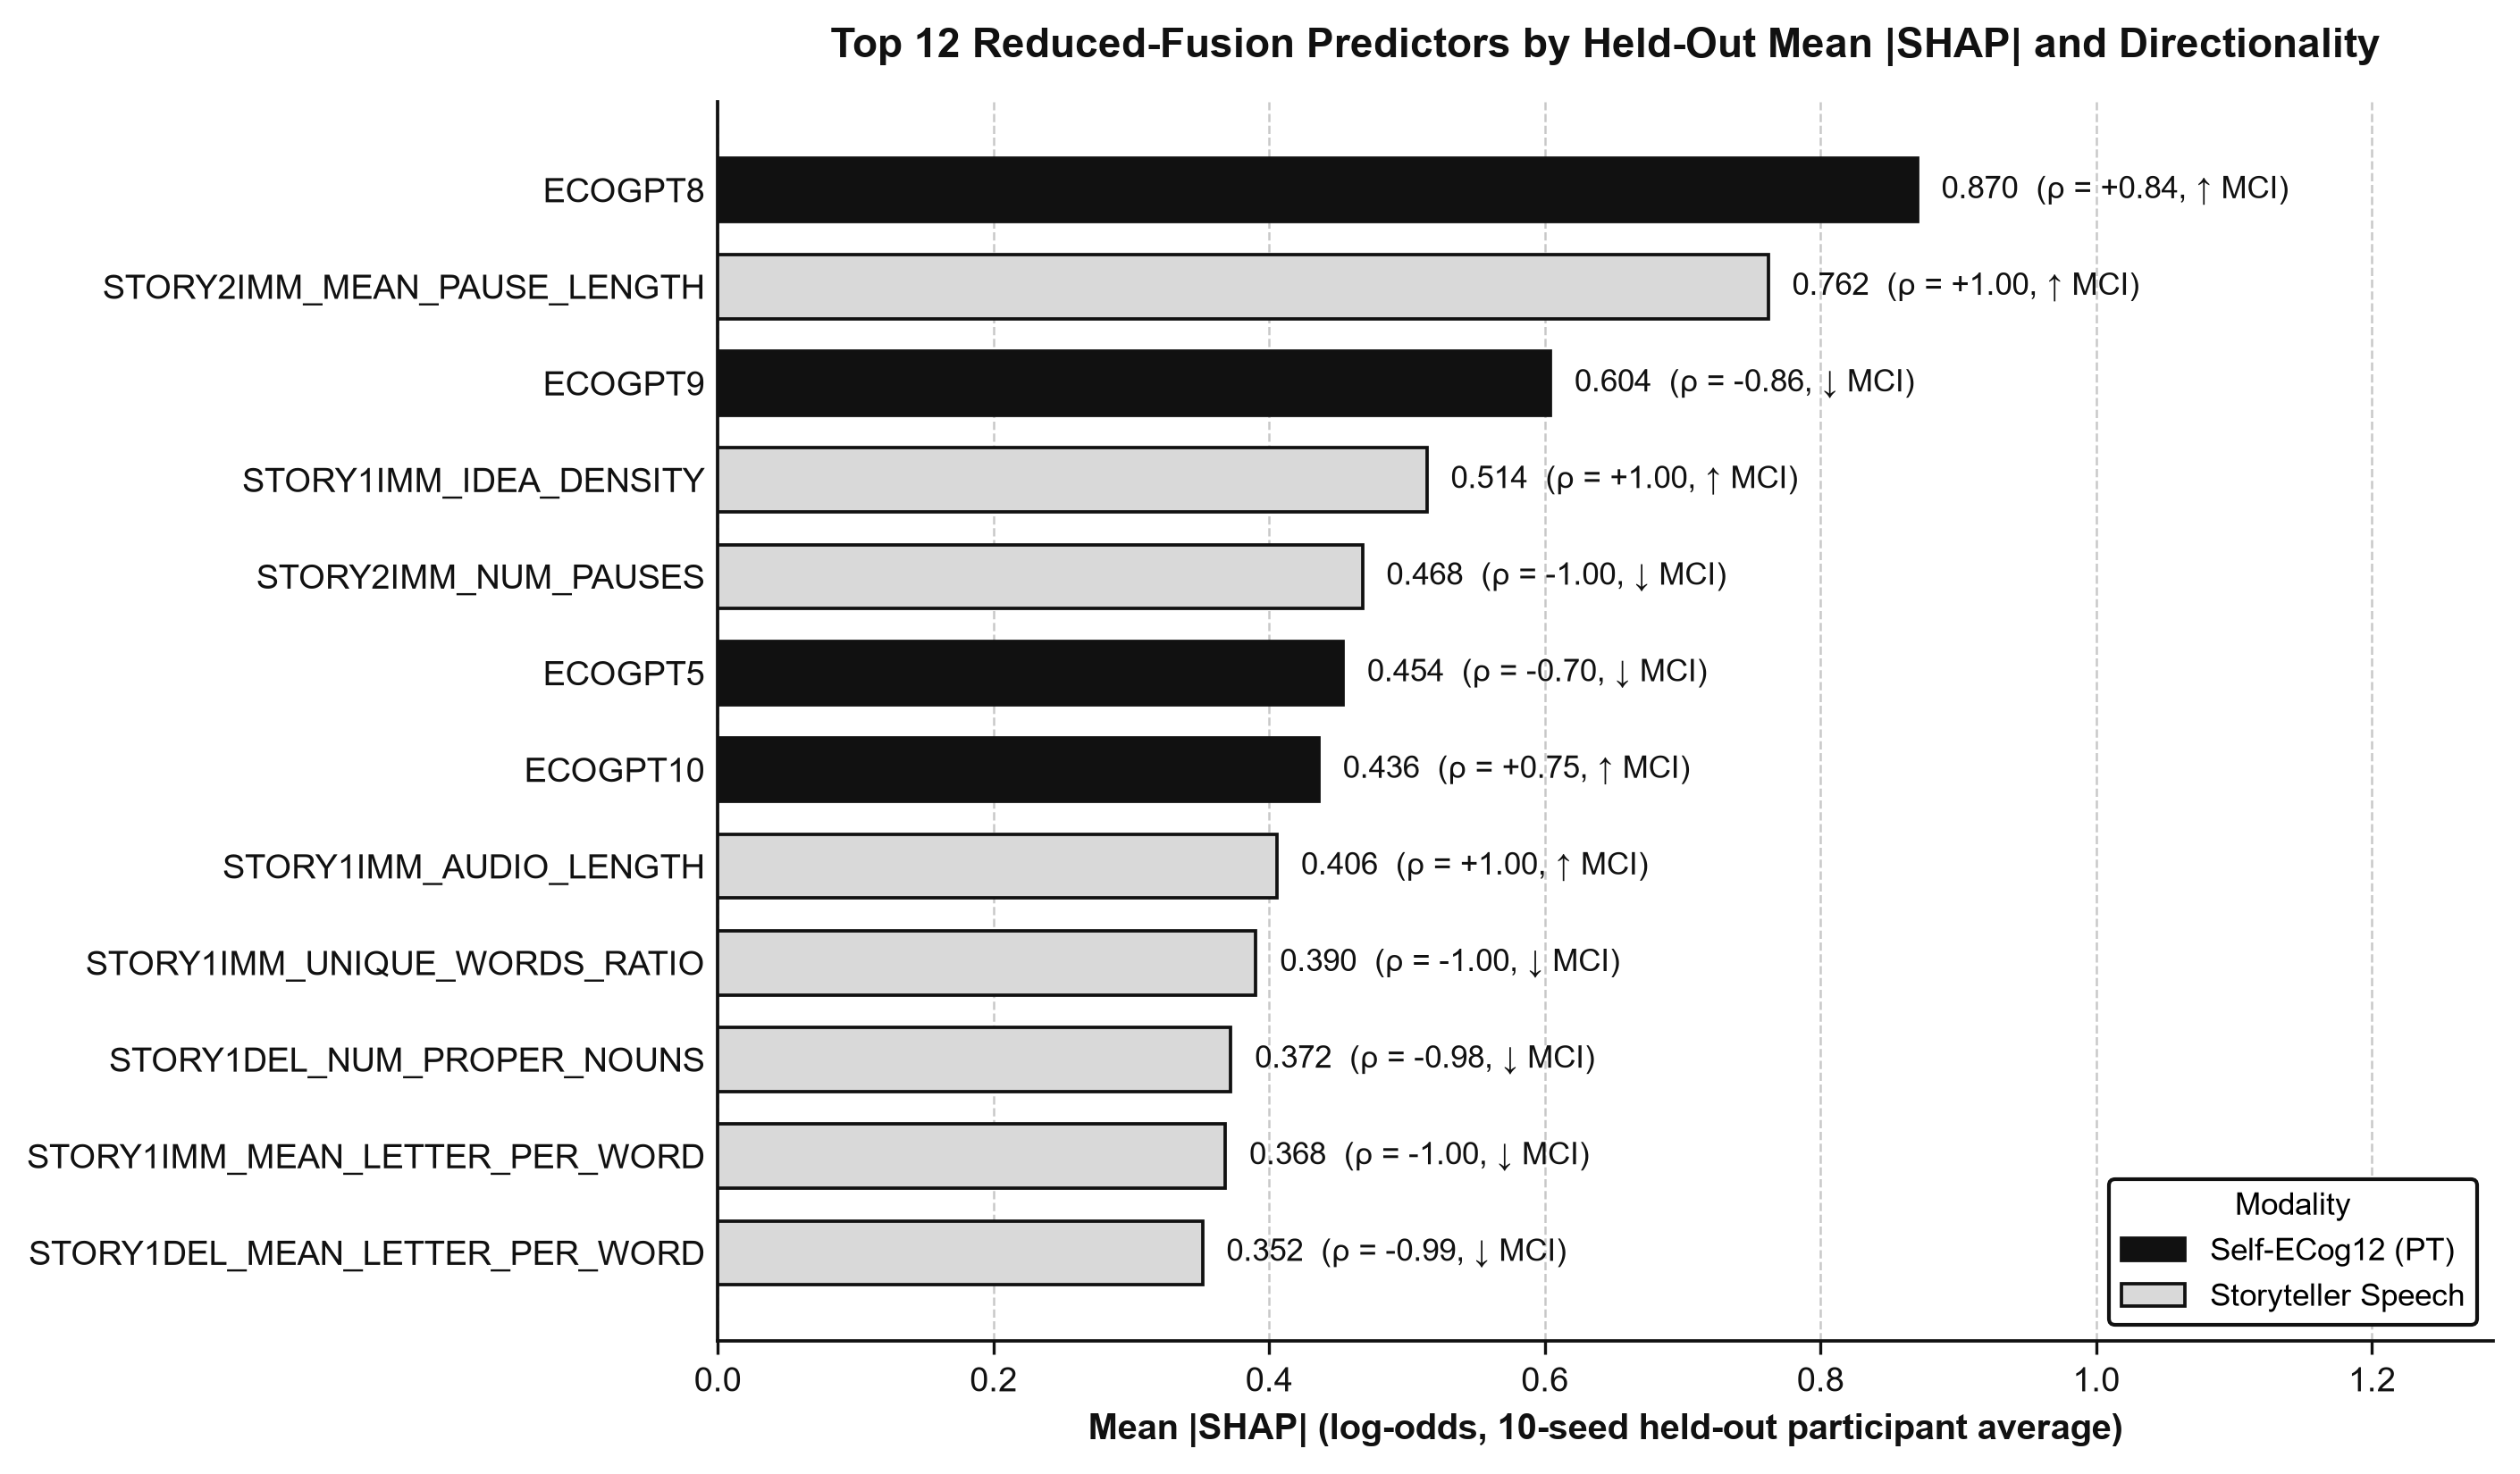

Saved Study 13B table to: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\dataset3_shap_explainability\study13b_shap_raw_directionality.csv
Saved Figure 4 to: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\figures\fig_shap_top12_reduced_fusion.png


In [15]:
# Figure 4 & Study 13B: Top-12 Reduced-Fusion SHAP Attributions + Raw-Feature Directionality (B&W, 300 DPI)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import spearmanr
from IPython.display import display

# 1. Verify required in-memory variables from previous cells
required_vars = [
    "PROJECT_DIR",
    "SHAP_DIR",
    "X_full23",
    "groups23",
    "shap_participant_results",
    "feature_interpretation",
]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise NameError(f"Run the earlier cells in 05_inference_shap_explainability.ipynb first. Missing: {missing_vars}")

REDUCED_MODEL = "Fusion without ECOGPT1 and ECOGPT2"
FIGURES_ROOT = Path(PROJECT_DIR) / "figures"
FIGURES_ROOT.mkdir(parents=True, exist_ok=True)

# 2. Extract top 12 reduced-fusion predictors (excluding missingness indicators)
top12 = (
    feature_interpretation[
        (feature_interpretation["Model"] == REDUCED_MODEL)
        & (~feature_interpretation["Feature"].str.endswith("__MISSING"))
    ]
    .sort_values("Mean_Absolute_SHAP", ascending=False)
    .head(12)
    .copy()
    .reset_index(drop=True)
)
top_features = top12["Feature"].tolist()

# 3. Compute participant-level raw-value-to-SHAP Spearman rho (n = 71 participants)
raw_df = X_full23[top_features].copy()
raw_df["PTID"] = pd.Series(groups23).astype(str).to_numpy()
raw_participant = raw_df.groupby("PTID", as_index=False).mean(numeric_only=True)

part_shap = shap_participant_results[REDUCED_MODEL].copy()
part_shap["PTID"] = part_shap["PTID"].astype(str)
shap_participant_mean = part_shap.groupby("PTID", as_index=False)[top_features].mean(numeric_only=True)

merged = raw_participant.merge(
    shap_participant_mean,
    on="PTID",
    suffixes=("_raw", "_shap"),
    how="inner",
    validate="one_to_one",
)

dir_rows = []
for _, row in top12.iterrows():
    feat = row["Feature"]
    valid = merged[[f"{feat}_raw", f"{feat}_shap"]].dropna()
    rho, pval = spearmanr(valid[f"{feat}_raw"], valid[f"{feat}_shap"])
    direction = (
        "Higher value -> higher MCI log-odds"
        if rho > 0
        else ("Higher value -> lower MCI log-odds" if rho < 0 else "Neutral")
    )
    dir_rows.append({
        "Feature": feat,
        "Modality": "Self-ECog12 (PT)" if row["Modality"] == "ECOG" else "Storyteller Speech",
        "Mean_Absolute_SHAP": float(row["Mean_Absolute_SHAP"]),
        "Top10_Seed_Frequency": float(row["Top10_Seed_Frequency"]),
        "N_Participants": int(len(valid)),
        "Spearman_Rho_Raw_vs_SHAP": float(rho),
        "Spearman_P_Value": float(pval),
        "Directionality": direction,
    })

direction_df = pd.DataFrame(dir_rows)
direction_csv = Path(SHAP_DIR) / "study13b_shap_raw_directionality.csv"
direction_df.to_csv(direction_csv, index=False)
display(direction_df.round(4))

# 4. Plot Figure 4 (clean black-and-white horizontal bar chart, 300 DPI)
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "axes.edgecolor": "#111111",
    "axes.linewidth": 0.9,
})

plot_df = direction_df.iloc[::-1].reset_index(drop=True)  # highest at top
y_pos = np.arange(len(plot_df))

bar_colors = [
    "#111111" if mod == "Self-ECog12 (PT)" else "#D9D9D9"
    for mod in plot_df["Modality"]
]

fig, ax = plt.subplots(figsize=(9.5, 5.6), dpi=300)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.barh(
    y_pos,
    plot_df["Mean_Absolute_SHAP"],
    height=0.66,
    color=bar_colors,
    edgecolor="#111111",
    linewidth=0.9,
    zorder=3,
)

max_x = plot_df["Mean_Absolute_SHAP"].max()
ax.set_xlim(0, max_x * 1.48)

for i, row in plot_df.iterrows():
    val = row["Mean_Absolute_SHAP"]
    rho = row["Spearman_Rho_Raw_vs_SHAP"]
    if np.isnan(rho):
        annot = f"{val:.3f}  (ρ = NA)"
    else:
        arrow = "↑ MCI" if rho > 0 else "↓ MCI"
        annot = f"{val:.3f}  (ρ = {rho:+.2f}, {arrow})"
    ax.text(
        val + max_x * 0.02,
        i,
        annot,
        va="center",
        ha="left",
        fontsize=8.5,
        color="#111111",
    )

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["Feature"], fontsize=9, color="#111111")
ax.set_xlabel("Mean |SHAP| (log-odds, 10-seed held-out participant average)", fontsize=9.5, fontweight="bold", color="#111111")
ax.set_title(
    "Top 12 Reduced-Fusion Predictors by Held-Out Mean |SHAP| and Directionality",
    fontsize=11,
    fontweight="bold",
    color="#111111",
    pad=12,
)

ax.xaxis.grid(True, linestyle="--", linewidth=0.6, color="#BBBBBB", alpha=0.8, zorder=0)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", labelsize=9, colors="#111111")
ax.tick_params(axis="y", length=0)

legend_handles = [
    Patch(facecolor="#111111", edgecolor="#111111", linewidth=0.9, label="Self-ECog12 (PT)"),
    Patch(facecolor="#D9D9D9", edgecolor="#111111", linewidth=0.9, label="Storyteller Speech"),
]
ax.legend(
    handles=legend_handles,
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#111111",
    framealpha=1.0,
    fontsize=8.5,
    title="Modality",
    title_fontsize=8.5,
)

plt.tight_layout()
fig4_path = FIGURES_ROOT / "fig_shap_top12_reduced_fusion.png"
plt.savefig(fig4_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print("Saved Study 13B table to:", direction_csv)
print("Saved Figure 4 to:", fig4_path)